In [2]:
import pyranges as pr
import os
import gzip
import pandas as pd
import numpy as np
from scipy.sparse import dok_matrix

from hicexplorer import hicConvertFormat
from hicexplorer import hicSumMatrices

import hicmatrix.HiCMatrix as hm
from hicexplorer import utilities
import scipy.sparse as sp

import tempfile
import copy

import pyBigWig
import gzip
from sklearn.preprocessing import MinMaxScaler
import random

import networkx as nx

import community as community_louvain

from icecream import ic

from collections import OrderedDict

import matplotlib.pyplot as plt
%matplotlib inline
import umap.umap_ as umap
reducer = umap.UMAP()

import sklearn.decomposition as skd


In [3]:
ROOT_PATH = '/Users/joachimwolff/data/epigenetic_graph_analyzer/'
path_interactions_E12_5_rep1 = ROOT_PATH + "phic/GSM6505214_Pinna_E12.5_CapHiC_Chicago_output_washU_text.txt.gz"
# path_interactions_E12_5_rep2 = ROOT_PATH + "phic/GSM6505215_Pinna_E12.5_CapHiC_3rdBioRep_Merged_cd_washU_text.txt.gz"

path_interactions_E14_5_rep1 = ROOT_PATH + "phic/GSM6505216_Pinna_E14.5_CapHiC_Chicago_output_washU_text.txt.gz"
# path_interactions_E14_5_rep2 = ROOT_PATH + "phic/GSM6505217_Pinna_E14.5_CapHiC_3rdBioRep_cd_washU_text.txt.gz"

path_output_bedpe_E12_5_rep1 = ROOT_PATH + "phic/GSM6505214_Pinna_E12.5_CapHiC_Chicago_output_washU_text.bedpe"
path_output_bedpe_E12_5_rep2 = ROOT_PATH + "phic/GSM6505215_Pinna_E12.5_CapHiC_3rdBioRep_Merged_cd_washU_text.bedpe"

path_output_bedpe_E14_5_rep1 = ROOT_PATH + "phic/GSM6505216_Pinna_E14.5_CapHiC_Chicago_output_washU_text.bedpe"
path_output_bedpe_E14_5_rep2 = ROOT_PATH + "phic/GSM6505217_Pinna_E14.5_CapHiC_3rdBioRep_cd_washU_text.bedpe"

path_output_cool_rep1 = ROOT_PATH + "phic/GSM6505214_Pinna_E12.5_CapHiC_Chicago_output_washU_text.cool"
path_output_cool_rep2 = ROOT_PATH + "phic/GSM6505215_Pinna_E12.5_CapHiC_3rdBioRep_Merged_cd_washU_text.cool"

path_output_cool_merged = ROOT_PATH + "phic/GSM6505215_Pinna_E12.5_CapHiC_merged.cool"


path_mm10_chromosome_size = ROOT_PATH + "mm10.chrom.sizes.sort"
path_promoter = ROOT_PATH + "mm10_promoter.bed"


# histones
path_histones_H3K3me2_E12_5_rep1 = ROOT_PATH + "histones/GSM6505186_H3K4me2_Pinna_E12.5_WT_rep1.scaled_0100.bw"
path_histones_H3K3me2_E12_5_rep2 = ROOT_PATH + "histones/GSM6505187_H3K4me2_Pinna_E12.5_WT_rep2.scaled_0100.bw"

path_histones_H3K3me2_E14_5_rep1 = ROOT_PATH + "histones/GSM6505192_H3K4me2_Pinna_E14.5_WT_rep1.scaled_0100.bw"
path_histones_H3K3me2_E14_5_rep2 = ROOT_PATH + "histones/GSM6505193_H3K4me2_Pinna_E14.5_WT_rep2.scaled_0100.bw"

path_histones_H3K27me3_E12_5_rep1  = ROOT_PATH + "histones/GSM6505188_H3K27me3_Pinna_E12.5_WT_rep1.scaled_0100.bw"
path_histones_H3K27me3_E12_5_rep2  = ROOT_PATH + "histones/GSM6505189_H3K27me3_Pinna_E12.5_WT_rep2.scaled_0100.bw"

path_histones_H3K27me3_E14_5_rep1  = ROOT_PATH + "histones/GSM6505194_H3K27me3_Pinna_E14.5_WT_rep1.scaled_0100.bw"
path_histones_H3K27me3_E14_5_rep2  = ROOT_PATH + "histones/GSM6505195_H3K27me3_Pinna_E14.5_WT_rep2.scaled_0100.bw"

path_histones_H3K27ac_E12_5_rep1  = ROOT_PATH + "histones/GSM6505184_H3K27ac_Pinna_E12.5_WT_rep1.scaled_0100.bw"
path_histones_H3K27ac_E12_5_rep2  = ROOT_PATH + "histones/GSM6505185_H3K27ac_Pinna_E12.5_WT_rep2.scaled_0100.bw"

path_histones_H3K27ac_E14_5_rep1  = ROOT_PATH + "histones/GSM6505190_H3K27ac_Pinna_E14.5_WT_rep1.scaled_0100.bw"
path_histones_H3K27ac_E14_5_rep2  = ROOT_PATH + "histones/GSM6505191_H3K27ac_Pinna_E14.5_WT_rep2.scaled_0100.bw"


# RNA
path_RNA_E12_5_rep1 = ROOT_PATH + "RNA/GSM6505221_RNAseq_E12.5-Pinna_TruSeq_1_cpm_100.bw"
path_RNA_E12_5_rep2 = ROOT_PATH + "RNA/GSM6505222_RNAseq_E12.5-Pinna_TruSeq_2_cpm_100.bw"
path_RNA_E12_5_rep3 = ROOT_PATH + "RNA/GSM6505223_RNAseq_E12.5-Pinna_TruSeq_3_cpm_100.bw"

path_RNA_E14_5_rep1 = ROOT_PATH + "RNA/GSM6505224_RNAseq_E14.5-Pinna_TruSeq_1_cpm_100.bw"
path_RNA_E14_5_rep2 = ROOT_PATH + "RNA/GSM6505225_RNAseq_E14.5-Pinna_TruSeq_2_cpm_100.bw"
path_RNA_E14_5_rep3 = ROOT_PATH + "RNA/GSM6505226_RNAseq_E14.5-Pinna_TruSeq_3_cpm_100.bw"

# ATAC
path_ATAC_E12_5_rep1 = ROOT_PATH + "ATAC/GSM6505176_ATAC_WT_E12.5_Pinna_SK_1.scaled_0100.bw"
path_ATAC_E12_5_rep2 = ROOT_PATH + "ATAC/GSM6505177_ATAC_WT_E12.5_Pinna_SK_2.scaled_0100.bw"
path_ATAC_E12_5_rep3 = ROOT_PATH + "ATAC/GSM6505178_ATAC_WT_E12.5_Pinna_SK_3.scaled_0100.bw"

path_ATAC_E14_5_rep1 = ROOT_PATH + "ATAC/GSM6505179_ATAC_E14.5_WT_Pinna_SK_1.scaled_0100.bw"
path_ATAC_E14_5_rep2 = ROOT_PATH + "ATAC/GSM6505180_ATAC_E14.5_WT_Pinna_SK_2.scaled_0100.bw"
path_ATAC_E14_5_rep3 = ROOT_PATH + "ATAC/GSM6505181_ATAC_E14.5_WT_Pinna_SK_3.scaled_0100.bw"



In [4]:
def washU_to_bedpe(path_input, path_output):
    pd_interactions = pd.read_table(path_input, header=None, sep='\t|,', compression='gzip')
    pd_interactions['name'] = [str(x) for x in range(len(pd_interactions))]
    pd_interactions.to_csv(path_output, index=False, header=False, sep='\t', mode='a')

In [45]:
washU_to_bedpe(path_interactions_E12_5_rep1, path_output_bedpe_E12_5_rep1)
# washU_to_bedpe(path_interactions_E12_5_rep2, path_output_bedpe_E12_5_rep2)
washU_to_bedpe(path_interactions_E14_5_rep1, path_output_bedpe_E14_5_rep1)
# washU_to_bedpe(path_interactions_E14_5_rep2, path_output_bedpe_E14_5_rep2)

In [5]:

def importInteractionsFromWashU(list_of_washU_files, chromosome_size_file, resolution):
    
    hic_matrix_list = []
    matrix_merged_csr = None
   
    for i, path_interactions in enumerate(list_of_washU_files):
        pd_interactions = pd.read_table(path_interactions, header=None, sep='\t|,', compression='gzip')
        
        chrom_sizes = OrderedDict()
        size_genome = 0
        with open(chromosome_size_file, 'r') as file:
            file_ = True
            while file_:
                file_ = file.readline().strip()
                if file_ != '':
                    line_split = file_.split('\t')
                    chrom_sizes[line_split[0]] = int(line_split[1])
                    size_genome += int(line_split[1])
        chrom_sizes = list(chrom_sizes.items())

        cut_intervals = []
        if isinstance(resolution, int):
            for chromosome in chrom_sizes:
                for interval in range(0, chromosome[1], resolution):
                    cut_intervals.append(tuple([chromosome[0], interval,
                                                min(chromosome[1], interval + resolution), 1.0]))
        else:
            restriction_cut_sites = pd.read_table(resolution, sep='\t')
            for row in restriction_cut_sites.iterrows():
                if row[1]['Chromosome'] in chrom_sizes:
                    if int(row[1]['End'] < chrom_sizes[row[1]['Chromosome']]):
                        cut_intervals.append(tuple([str(row[1]['Chromosome']), int(row[1]['Start']), int(row[1]['End']), 1.0]))
        hic_matrix_csr = dok_matrix((len(cut_intervals), len(cut_intervals)))

        hic_matrix = hm.hiCMatrix()
        hic_matrix.setMatrix(hic_matrix_csr, cut_intervals)
        for row in pd_interactions.iterrows():
            
            chromosome_1 = str(row[1][0])
            start_1 = int(row[1][1]) + 1
            end_1 = int(row[1][2]) - 1

            chromosome_2 = str(row[1][3])
            start_2 = int(row[1][4]) + 1
            end_2 = int(row[1][5]) - 1

            value = float(row[1][6])
            
            bin_id_1 = hic_matrix.getRegionBinRange(chromosome_1, start_1, end_1)
            bin_id_2 = hic_matrix.getRegionBinRange(chromosome_2, start_2, end_2)

            try:
                hic_matrix.matrix[bin_id_1, bin_id_2] = value
            except IndexError as exp:
                pass
        hic_matrix.matrix = hic_matrix.matrix.tocsr()
        hic_matrix_list.append(hic_matrix)
        if matrix_merged_csr is None:
            matrix_merged_csr = hic_matrix_list[0].matrix.tocsr()
        else:
            matrix_merged_csr += hic_matrix_list[i].matrix.tocsr()
        
    hic_matrix_list.append(matrix_merged_csr)
    return hic_matrix_list

In [8]:
chromosomeSizes = path_mm10_chromosome_size
matrix = ROOT_PATH + "phic/GSM6505208_Md_CapHiC_Merged_All-Tr_2ndBioRep_Chicago_output_washU_text.csv"



In [104]:
pd.read_table(os.path.join(ROOT_PATH, 'raw_pc_hic/restriction_cut_sites.csv'), sep='\t')

,Chromosome,Start,End
0,chr1,3004106,3005820
1,chr1,3005821,3008316
2,chr1,3008317,3008894
3,chr1,3008895,3009813
4,chr1,3009814,3012423
...,...,...,...
524331,chrY,86432294,86441076
524332,chrY,87307178,87308086
524333,chrY,88236833,88237614
524334,chrY,89979359,89979992


In [51]:
pd_interactions_Pinna_E12_5 = pd.read_table(path_interactions_E12_5_rep1, header=None, sep='\t|,', compression='gzip')


In [55]:
pyrange_promoter = pr.read_bed(path_promoter)

In [58]:
pyrange_promoter[pyrange_promoter.Name == 'Hoxa6_1']

,Chromosome,Start,End,Name,Score,Strand,ThickStart,ThickEnd
18708,chr6,52208661,52208721,Hoxa6_1,900,-,52208661,52208672


In [63]:
pyrange_promoter[pyrange_promoter.Name == 'Hoxaas3_1']

,Chromosome,Start,End,Name,Score,Strand,ThickStart,ThickEnd
18705,chr6,52175157,52175217,Hoxaas3_1,900,+,52175206,52175217


In [54]:
pd_interactions_Pinna_E12_5

,0,1,2,3,4,5,6
0,chr1,3100832,3102475,chr1,88213919,88219911,6.23
1,chr1,3100832,3102475,chr1,88219912,88220831,6.23
2,chr1,3100832,3102475,chr17,23505926,23514823,13.64
3,chr1,3100832,3102475,chr9,16624619,16625522,5.74
4,chr1,3100832,3102475,chrUn_GL456239,7011,8069,11.43
...,...,...,...,...,...,...,...
137763,chrY,1245110,1246846,chrY,1025589,1026886,6.65
137764,chrY,1245110,1246846,chrY,1168639,1169738,5.06
137765,chrY,1276141,1286958,chrY,1013180,1014934,5.57
137766,chrY,1304307,1309275,chrY,939340,940729,5.02


In [66]:
hoxa6_region = pd_interactions_Pinna_E12_5[(pd_interactions_Pinna_E12_5[0] == 'chr6') & (pd_interactions_Pinna_E12_5[1] >= 52200000) & (pd_interactions_Pinna_E12_5[2] <= 52300000) ]
hoxa6_region[(hoxa6_region[0] != hoxa6_region[3])]

,0,1,2,3,4,5,6
103287,chr6,52201567,52207513,chr9,60901938,60909350,5.12


In [69]:
hoxaas3_region = pd_interactions_Pinna_E12_5[(pd_interactions_Pinna_E12_5[0] == 'chr6') & (pd_interactions_Pinna_E12_5[1] >= 52170000) & (pd_interactions_Pinna_E12_5[2] <= 52300000) ]
hoxaas3_region[(hoxaas3_region[0] != hoxaas3_region[3])]

,0,1,2,3,4,5,6
103287,chr6,52201567,52207513,chr9,60901938,60909350,5.12


In [ ]:
# chr6	52164817	52164877	Hoxa2_1

In [6]:
interaction_matrices_sample_Pinna_12_5 = importInteractionsFromWashU([path_interactions_E12_5_rep1], path_mm10_chromosome_size, resolution=os.path.join(ROOT_PATH, 'raw_pc_hic/restriction_cut_sites.csv'))
interaction_matrices_sample_Pinna_14_5 = importInteractionsFromWashU([path_interactions_E14_5_rep1], path_mm10_chromosome_size, resolution=os.path.join(ROOT_PATH, 'raw_pc_hic/restriction_cut_sites.csv'))


In [36]:
# chr6	52164817	52164877	Hoxa2_1
interaction_matrices_sample_Pinna_12_5[0].getRegionBinRange('chr6', 52164817, 52164877)

(391780, 391780)

In [27]:
interaction_matrices_sample_Pinna_12_5[0].matrix[391780, :]

<1x524336 sparse matrix of type '<class 'numpy.float64'>'
	with 47 stored elements in Compressed Sparse Row format>

In [38]:
def createSampleInteractionMatrix(path_promoter, chic_matrix):
    pyrange_promoter = pr.read_bed(path_promoter)

    matrix_list = []
    bait_list = []
    for index, row in pyrange_promoter.as_df().iterrows():
        bait_location = row[['Chromosome', 'Start', 'End']]
        if bait_location[0] == 'chr6' and bait_location[1] >= 52164817 and bait_location[2] <= 52164877:
            ic(bait_location, row)
            # ic(chic_matrix[0].getRegionBinRange(bait_location[0], bait_location[1], bait_location[2]))
        
        view_point_start, _ = chic_matrix[0].getRegionBinRange(bait_location[0], bait_location[1] +1, bait_location[2]-1)
        matrix_list.append(chic_matrix[0].matrix[view_point_start, :])
        bait_list.append(row[['Name']])
        


    # Assuming you have a list of CSR matrices: matrix_list
    sample_matrix = sp.vstack(matrix_list)
    return sample_matrix, bait_list

In [39]:
sample_matrix_Pinna_E12_5, bait_list_Pinna_E12_5 = createSampleInteractionMatrix(path_promoter, interaction_matrices_sample_Pinna_12_5)
sample_matrix_Pinna_E14_5, bait_list_Pinna_E14_5 = createSampleInteractionMatrix(path_promoter, interaction_matrices_sample_Pinna_14_5)

ERROR:hicmatrix.HiCMatrix:Index error
Traceback (most recent call last):
  File "/Users/joachimwolff/opt/miniconda3_x86/envs/ega/lib/python3.10/site-packages/hicmatrix/HiCMatrix.py", line 261, in getRegionBinRange
    startbin = sorted(self.interval_trees[chrname][startpos:startpos + 1])[0].data
IndexError: list index out of range


TypeError: cannot unpack non-iterable NoneType object

In [37]:
sample_matrix_Pinna_E12_5[8767, :]

<1x524336 sparse matrix of type '<class 'numpy.float64'>'
	with 7 stored elements in Compressed Sparse Row format>

In [33]:
interaction_matrices_sample_Pinna_12_5[0].matrix[391780, :]

<1x524336 sparse matrix of type '<class 'numpy.float64'>'
	with 47 stored elements in Compressed Sparse Row format>

In [20]:
bait_list_Pinna_E14_5_df = pd.DataFrame(bait_list_Pinna_E14_5, columns=['Name'])
bait_list_Pinna_E14_5_df[bait_list_Pinna_E14_5_df["Name"] == "Hoxa2_1"]


,Name
8767,Hoxa2_1


In [21]:
def createGraphAndFindCommunities(sample_matrix, bait_list, path_output_graphml):
    G = nx.Graph()
    number_of_samples = sample_matrix.shape[0]
    bait_ids, OE_ids = sample_matrix.nonzero()
    for i, (bait, OE) in enumerate(zip(bait_ids, OE_ids)):
        if bait == 8767:
            ic(bait, OE, sample_matrix.data[i])
        if (bait != OE):
            G.add_weighted_edges_from([(bait, OE+number_of_samples, sample_matrix.data[i])])
            G.nodes[OE + number_of_samples]['colorType'] = "orange"


    for bait in bait_ids:
        G.nodes[bait]['name'] = bait_list[bait][0]
        G.nodes[bait]['colorType'] = "green"

    partition = community_louvain.best_partition(G)

    for node, partition_id in partition.items():
        G.nodes[node]['partition'] = partition_id
        G.nodes[node]['partition_color'] = partition_id


    nx.write_graphml(G, path_output_graphml)

    return G, partition

In [22]:
G_Pinna_E12_5, partition_Pinna_E12_5 = createGraphAndFindCommunities(sample_matrix_Pinna_E12_5, bait_list_Pinna_E12_5, ROOT_PATH + "Pinna_E12_5.graphml")
G_Pinna_E14_5, partition_Pinna_E14_5 = createGraphAndFindCommunities(sample_matrix_Pinna_E14_5, bait_list_Pinna_E14_5, ROOT_PATH + "Pinna_E14_5.graphml")

{10: 0,
 284347: 0,
 284372: 0,
 284377: 0,
 285038: 0,
 287332: 0,
 287661: 0,
 287832: 0,
 13: 1,
 287999: 1,
 14: 1,
 19: 0,
 285047: 0,
 285108: 0,
 287592: 0,
 287632: 0,
 287634: 0,
 287644: 0,
 287647: 0,
 287651: 0,
 287671: 0,
 287689: 0,
 1466086: 0,
 20: 2,
 288118: 2,
 290739: 2,
 35: 3,
 297860: 3,
 297867: 3,
 297868: 3,
 298165: 3,
 298186: 3,
 298192: 3,
 298201: 3,
 298203: 3,
 298336: 3,
 298337: 3,
 298341: 3,
 298343: 3,
 298344: 3,
 298354: 3,
 298355: 3,
 298360: 3,
 298362: 3,
 298373: 3,
 298374: 3,
 298382: 3,
 298390: 3,
 298393: 3,
 298394: 3,
 298405: 3,
 298413: 3,
 334874: 3,
 399071: 3,
 41: 4,
 299049: 4,
 299052: 4,
 299055: 4,
 299154: 4,
 299234: 4,
 300205: 4,
 50: 5,
 302127: 5,
 53: 6,
 301213: 6,
 301593: 6,
 301716: 6,
 301721: 6,
 301723: 6,
 1548124: 6,
 58: 7,
 308599: 7,
 308605: 7,
 308640: 7,
 308641: 7,
 308670: 7,
 308673: 7,
 308674: 7,
 311767: 7,
 311780: 7,
 392350: 7,
 392351: 7,
 59: 8,
 311552: 8,
 61: 9,
 308760: 9,
 309087: 9,
 3

In [18]:
partition_Pinna_E12_5[8767]

KeyError: 8767

In [19]:
partition_Pinna_E14_5[8767]

KeyError: 8767

In [17]:
for bait in bait_list_Pinna_E12_5:
    if "Hoxa" in bait[0]:
        print(bait)

Name    Hoxaas2_1
Name: 8138, dtype: object
Name    Hoxaas3_1
Name: 8140, dtype: object
Name    Hoxaas3_2
Name: 8141, dtype: object
Name    Hoxa11os_1
Name: 8142, dtype: object
Name    Hoxa11os_2
Name: 8143, dtype: object
Name    Hoxa1_1
Name: 8766, dtype: object
Name    Hoxa2_1
Name: 8767, dtype: object
Name    Hoxa4_1
Name: 8768, dtype: object
Name    Hoxa6_1
Name: 8769, dtype: object
Name    Hoxa9_1
Name: 8770, dtype: object
Name    Hoxa10_2
Name: 8772, dtype: object
Name    Hoxa10_1
Name: 8773, dtype: object
Name    Hoxa11_1
Name: 8774, dtype: object
Name    Hoxa13_1
Name: 8775, dtype: object


In [77]:
for bait in bait_list_Pinna_E14_5:
    if "Hoxa" in bait[0]:
        print(bait)

Name    Hoxaas2_1
Name: 8138, dtype: object
Name    Hoxaas3_1
Name: 8140, dtype: object
Name    Hoxaas3_2
Name: 8141, dtype: object
Name    Hoxa11os_1
Name: 8142, dtype: object
Name    Hoxa11os_2
Name: 8143, dtype: object
Name    Hoxa1_1
Name: 8766, dtype: object
Name    Hoxa2_1
Name: 8767, dtype: object
Name    Hoxa4_1
Name: 8768, dtype: object
Name    Hoxa6_1
Name: 8769, dtype: object
Name    Hoxa9_1
Name: 8770, dtype: object
Name    Hoxa10_2
Name: 8772, dtype: object
Name    Hoxa10_1
Name: 8773, dtype: object
Name    Hoxa11_1
Name: 8774, dtype: object
Name    Hoxa13_1
Name: 8775, dtype: object


In [17]:
def createDataMatrixFromBigWig(sample_matrix, interaction_matrix, path_bigwig_list):
    list_of_data_matrices = []
    sample, interaction = sample_matrix.nonzero()

    for file_path in path_bigwig_list:
        # Open the bigwig file
        bw = pyBigWig.open(file_path)

        data_matrix = dok_matrix(sample_matrix.shape)
        for sample_bin, interaction_bin in zip(sample, interaction):
            chromosome, start, end , _ = interaction_matrix.getBinPos(interaction_bin)
            
            # Read the data from the bigwig file
            value = bw.stats(chromosome, start, end)
            data_matrix[sample_bin, interaction_bin] = value[0]
        
        list_of_data_matrices.append(data_matrix.tocsr())
    return list_of_data_matrices

In [73]:
bigwig_files_Pinna_E12_5 = [path_histones_H3K27ac_E12_5_rep1, path_histones_H3K27ac_E12_5_rep2,  path_histones_H3K27me3_E12_5_rep1, path_histones_H3K27me3_E12_5_rep2,path_histones_H3K3me2_E12_5_rep1, path_histones_H3K3me2_E12_5_rep2,  path_RNA_E12_5_rep1, path_RNA_E12_5_rep2, path_RNA_E12_5_rep3,  path_ATAC_E12_5_rep1, path_ATAC_E12_5_rep2, path_ATAC_E12_5_rep3]
bigwig_files_Pinna_E14_5 = [path_histones_H3K27ac_E14_5_rep1, path_histones_H3K27ac_E14_5_rep2, path_histones_H3K27me3_E14_5_rep1, path_histones_H3K27me3_E14_5_rep2, path_histones_H3K3me2_E14_5_rep1, path_histones_H3K3me2_E14_5_rep2,path_RNA_E14_5_rep1, path_RNA_E14_5_rep2, path_RNA_E14_5_rep3, path_ATAC_E14_5_rep1, path_ATAC_E14_5_rep2, path_ATAC_E14_5_rep3]
data_matrix_list_Pinna_E12_5 = createDataMatrixFromBigWig(sample_matrix_Pinna_E12_5, interaction_matrices_sample_Pinna_12_5[0], bigwig_files_Pinna_E12_5)
data_matrix_list_Pinna_E14_5 = createDataMatrixFromBigWig(sample_matrix_Pinna_E14_5, interaction_matrices_sample_Pinna_14_5[0], bigwig_files_Pinna_E14_5)

In [20]:
def createCommunityMatrix(sample_matrix, list_of_data_matrices, partition):
    matrix_list = [sample_matrix.tocsr(), *list_of_data_matrices]
    # Create matrix per community
    community_matrix_mean = np.zeros((max(partition.values())+1, len(matrix_list)))
    community_matrix_median = np.zeros((max(partition.values())+1, len(matrix_list)))
    community_matrix_sum = np.zeros((max(partition.values())+1, len(matrix_list)))

    elements_per_community = np.zeros(max(partition.values())+1)

    baits_partition_dict = {key: value for key, value in partition.items() if key < sample_matrix.shape[0]}
    for community_id in baits_partition_dict:
        for i, matrix in enumerate(matrix_list):
            try:
                community_matrix_mean[baits_partition_dict[community_id], i] += np.nan_to_num(np.mean(np.nan_to_num(matrix[community_id, :].data)))
                community_matrix_median[baits_partition_dict[community_id], i] += np.nan_to_num(np.median(np.nan_to_num(matrix[community_id, :].data)))
                community_matrix_sum[baits_partition_dict[community_id], i] += np.nan_to_num(np.sum(np.nan_to_num(matrix[community_id, :].data)))
            except (IndexError, KeyError):
                ic(i)
                ic(community_id)
        elements_per_community[baits_partition_dict[community_id]] += 1

    community_matrix_mean_normalized = community_matrix_mean / elements_per_community[:, np.newaxis]
    community_matrix_median_normalized = community_matrix_median / elements_per_community[:, np.newaxis]
    community_matrix_sum_normalized = community_matrix_sum / elements_per_community[:, np.newaxis]

    scaler = MinMaxScaler()
    community_matrix_mean = scaler.fit_transform(community_matrix_mean[np.any(community_matrix_mean != 0, axis=1)])
    community_matrix_median = scaler.fit_transform(community_matrix_median[np.any(community_matrix_median != 0, axis=1)])
    community_matrix_sum = scaler.fit_transform(community_matrix_sum[np.any(community_matrix_sum != 0, axis=1)])
    community_matrix_mean_normalized = scaler.fit_transform(community_matrix_mean_normalized[np.any(community_matrix_mean_normalized != 0, axis=1)])
    community_matrix_median_normalized = scaler.fit_transform(community_matrix_median_normalized[np.any(community_matrix_median_normalized != 0, axis=1)])
    community_matrix_sum_normalized = scaler.fit_transform(community_matrix_sum_normalized[np.any(community_matrix_sum_normalized != 0, axis=1)])

    return community_matrix_mean, community_matrix_median, community_matrix_sum, community_matrix_mean_normalized, community_matrix_median_normalized, community_matrix_sum_normalized


In [74]:
different_communities_Pinna_E_12_5 = createCommunityMatrix(sample_matrix_Pinna_E12_5, data_matrix_list_Pinna_E12_5, partition_Pinna_E12_5)
different_communities_Pinna_E_14_5 = createCommunityMatrix(sample_matrix_Pinna_E14_5, data_matrix_list_Pinna_E14_5, partition_Pinna_E14_5) 


In [23]:
def plotPCA(matrix, type_of_matrix):
    pca1, pca2 = skd.PCA(n_components=2).fit_transform(matrix).T
    title = "Scatter Plot PCA"
    # list_of_titles = ["Interaction", " act H3K3me2_rep1", "act H3K3me2_rep2", "rep H3K27me3_rep1", "rep H3K27me3_rep2", "act H3K27ac_rep1", "act H3K27ac_rep2", "RNA_rep1", "RNA_rep2", "RNA_rep3", "ATAC_rep1", "ATAC_rep2", "ATAC_rep3", "Number of Interactions"]
    list_of_titles = ["Interaction", " act H3K3me2_rep1",  "rep H3K27me3_rep1", "act H3K27ac_rep1","RNA_rep1",  "ATAC_rep1"]
    # list_of_colorings = community_matrix_median.T.tolist()

    list_of_colorings = matrix.T[[0,1,3,5,7,10]].tolist()

    plotEmbedding([pca1, pca2], list_of_titles, list_of_colorings, type_of_matrix + " " + title)



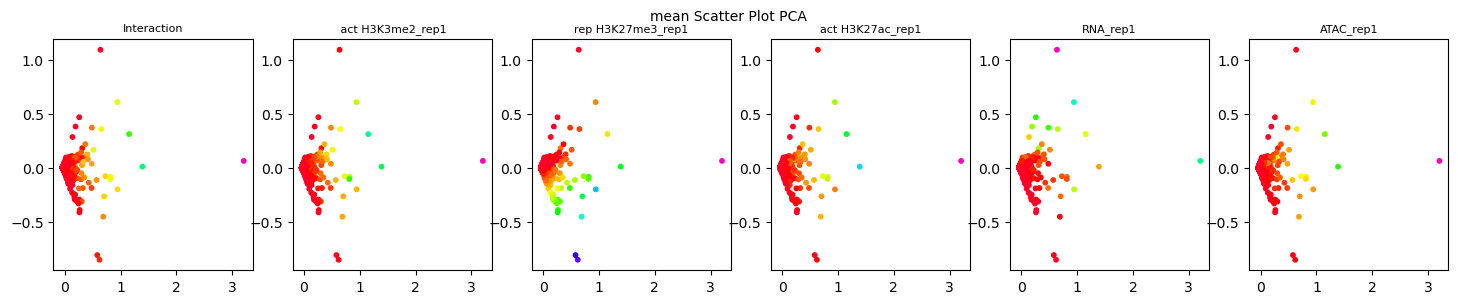

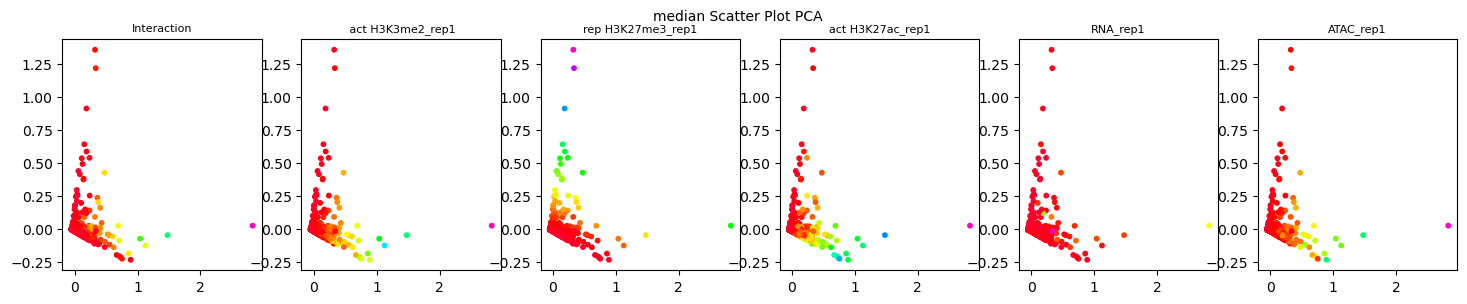

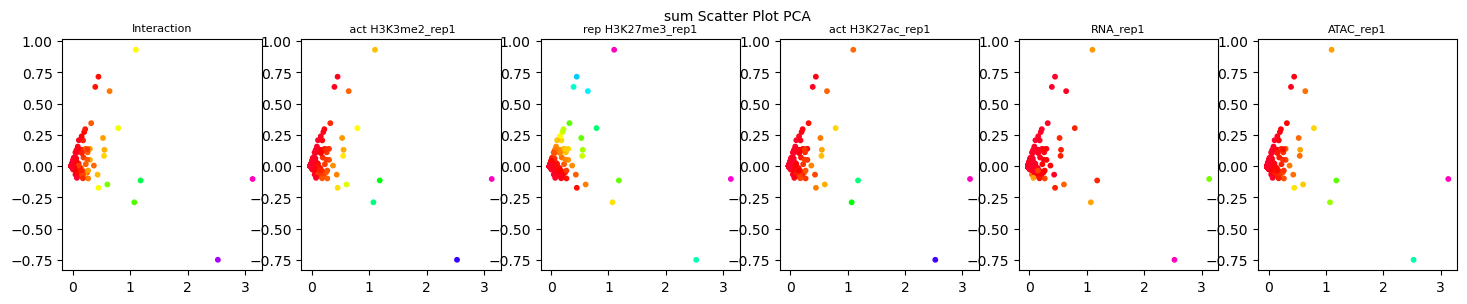

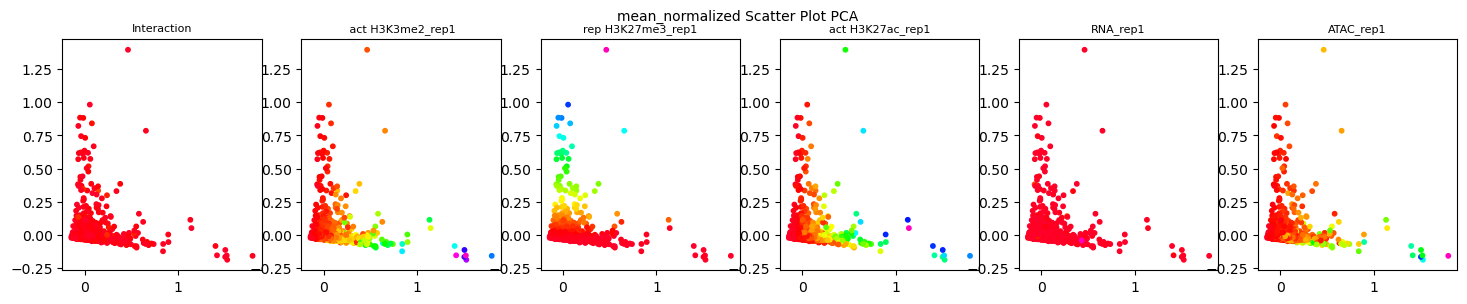

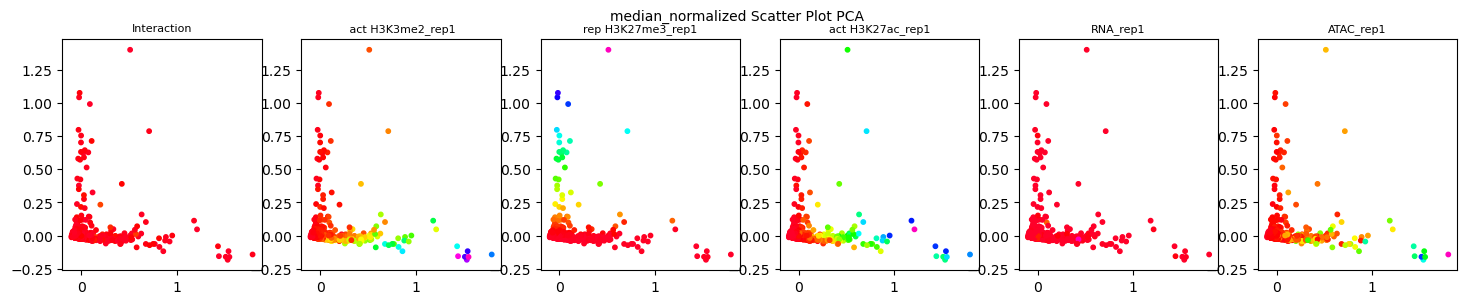

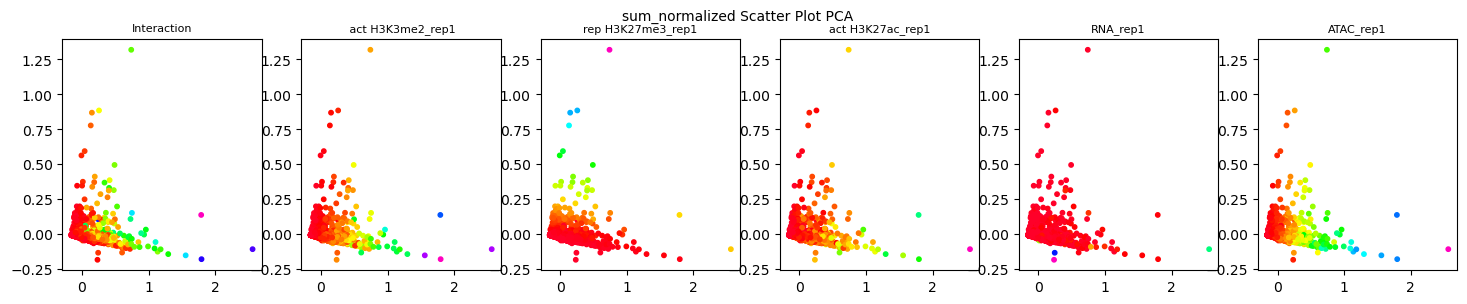

In [75]:
for i, title in enumerate(["mean", "median", "sum", "mean_normalized", "median_normalized", "sum_normalized"]):
    
    plotPCA(different_communities_Pinna_E_12_5[i], title)

In [29]:
def plotUMAP(matrix, type_of_matrix):
    embedding = reducer.fit_transform(matrix)
    title = "Scatter Plot PCA"
    # list_of_titles = ["Interaction", " act H3K3me2_rep1", "act H3K3me2_rep2", "rep H3K27me3_rep1", "rep H3K27me3_rep2", "act H3K27ac_rep1", "act H3K27ac_rep2", "RNA_rep1", "RNA_rep2", "RNA_rep3", "ATAC_rep1", "ATAC_rep2", "ATAC_rep3", "Number of Interactions"]
    list_of_titles = ["Interaction", " act H3K3me2_rep1",  "rep H3K27me3_rep1", "act H3K27ac_rep1","RNA_rep1",  "ATAC_rep1"]
    # list_of_colorings = community_matrix_median.T.tolist()

    list_of_colorings = matrix.T[[0,1,3,5,7,10]].tolist()

    plotEmbedding([embedding[:, 0], embedding[:, 1]], list_of_titles, list_of_colorings, type_of_matrix + " " + title)

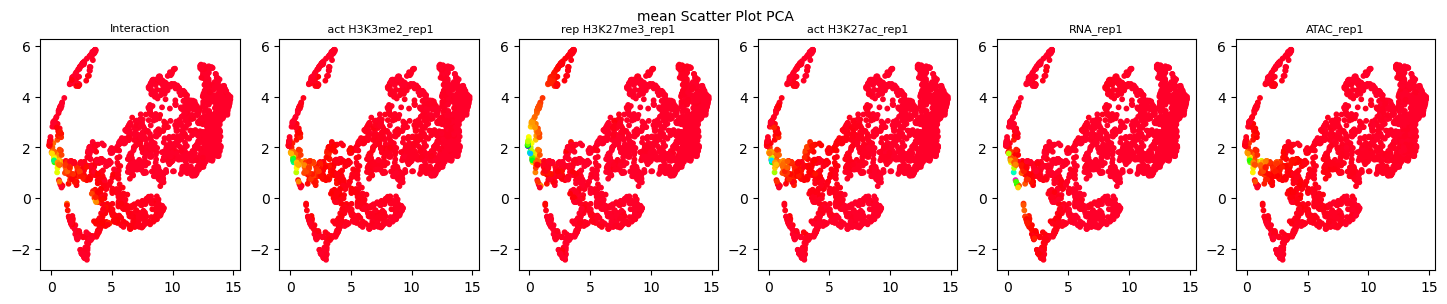

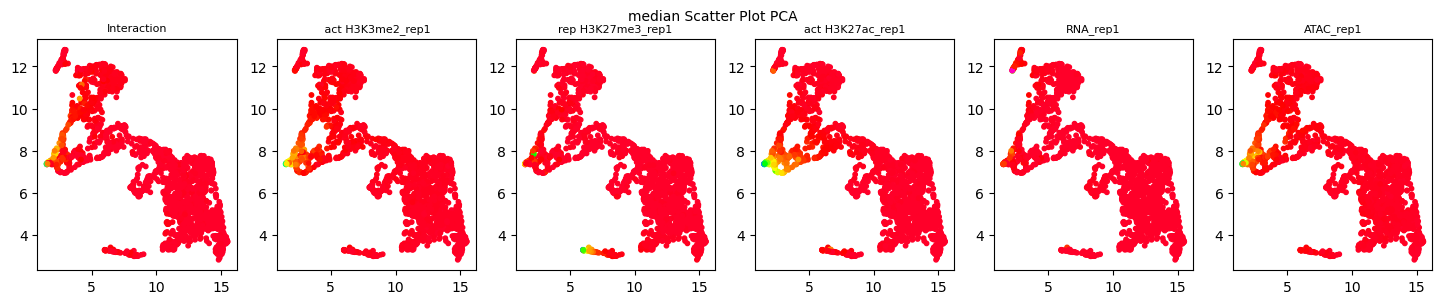

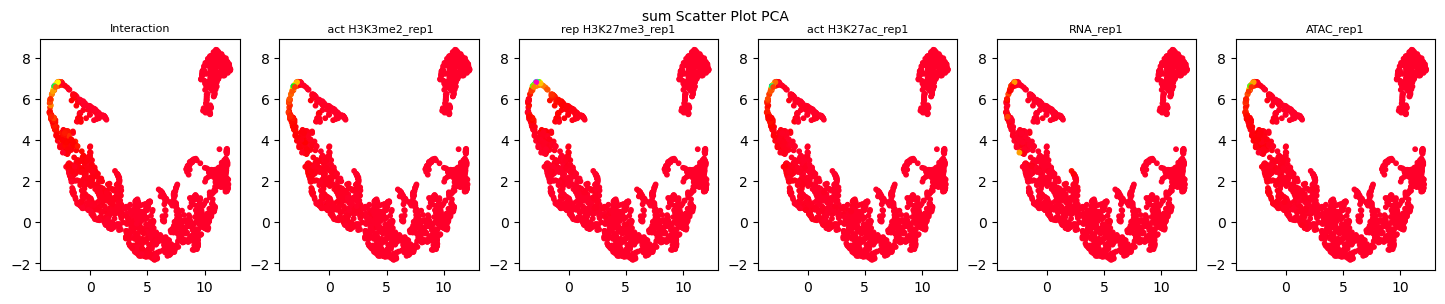

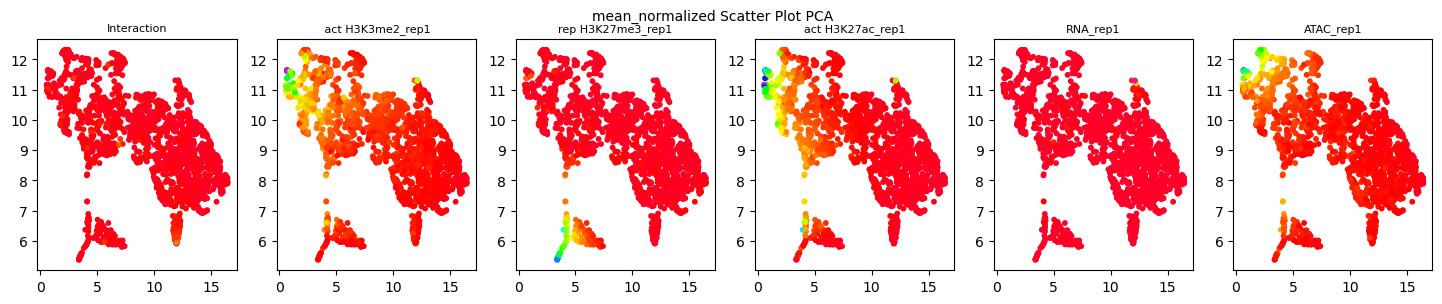

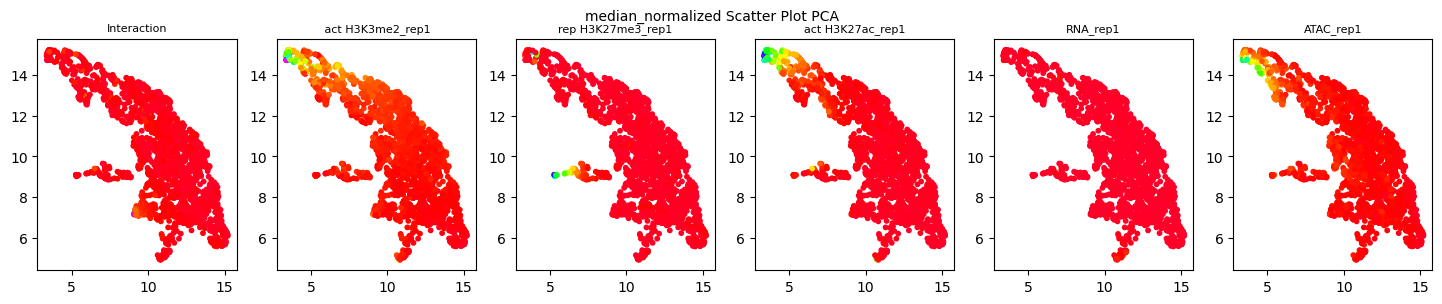

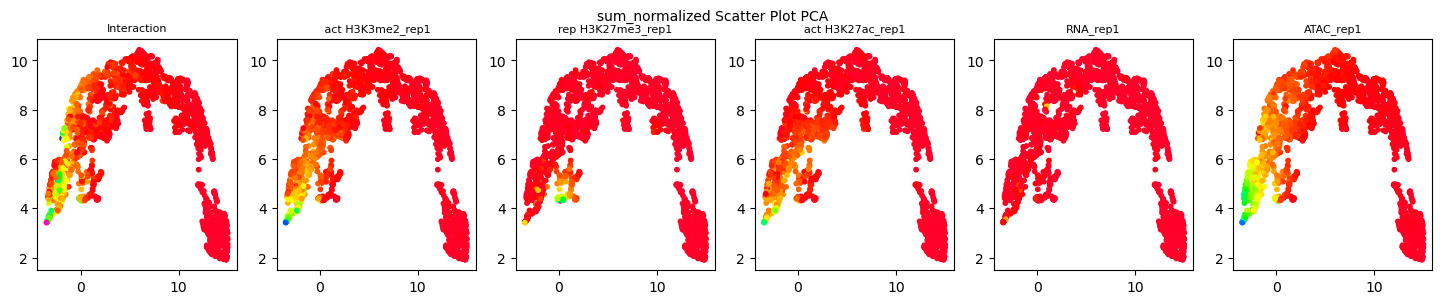

In [76]:
for i, title in enumerate(["mean", "median", "sum", "mean_normalized", "median_normalized", "sum_normalized"]):
    
    plotUMAP(different_communities_Pinna_E_12_5[i], title)

In [33]:
for i, title in enumerate(["mean", "median", "sum", "mean_normalized", "median_normalized", "sum_normalized"]):
    
    plotPCA(different_communities_Pinna_E_14_5[i], title)

In [201]:
plotPCA(different_communities_Pinna_E_14_5[0] - different_communities_Pinna_E_12_5[0], title)

ValueError: operands could not be broadcast together with shapes (2349,13) (2457,13) 

In [37]:
from sklearn.neighbors import NearestNeighbors

knn = NearestNeighbors()



In [26]:
def plotEmbedding(list_of_embeddings, list_of_subtitles, list_of_colorings, title_of_plot, fontsize=8):
    fig, axs = plt.subplots(1, len(list_of_subtitles), figsize=(3 * len(list_of_subtitles), 3))

    for i, (title, coloring) in enumerate(zip(list_of_subtitles, list_of_colorings)):
        # Plot the first version
        axs[i].scatter(list_of_embeddings[0], list_of_embeddings[1], c=coloring, cmap='gist_rainbow', s=10)  # Change the value of s to adjust the dot size
        axs[i].set_title(title, fontsize=fontsize)

    fig.suptitle(title_of_plot, fontsize=fontsize+2)
    plt.show()

In [27]:
import matplotlib.pyplot as plt

In [328]:
len(different_communities_Pinna_E_12_5[-1])

469

In [325]:
plt.figure(figsize=(15, 8))
plot_matrix = different_communities_Pinna_E_14_5[-1] - different_communities_Pinna_E_12_5[-1]
sorted_indices = np.argsort(plot_matrix[:, 1])
sorted_matrix = plot_matrix[sorted_indices]
plt.imshow(sorted_matrix, cmap='RdBu_r', interpolation='nearest', aspect='auto')
plt.title('Community Matrix')
plt.xlabel('Matrix Columns')
plt.ylabel('Community ID')
plt.colorbar()

# Add ticks per column with text in 45-degree angle
ticks = ["Interaction", " act H3K3me2_rep1", "act H3K3me2_rep2", "rep H3K27me3_rep1", "rep H3K27me3_rep2", "act H3K27ac_rep1", "act H3K27ac_rep2", "RNA_rep1", "RNA_rep2", "RNA_rep3", "ATAC_rep1", "ATAC_rep2", "ATAC_rep3", "Number of Interactions"]
plt.xticks(range(len(ticks)), ticks, rotation=90, fontsize=8)



ValueError: operands could not be broadcast together with shapes (1962,13) (469,13) 

<Figure size 1500x800 with 0 Axes>

In [ ]:
plt.show()

In [ ]:
elements_per_community

array([ 55., 228., 161., ...,   1.,   1.,   1.])

In [ ]:
np.mean(matrix[community_id, :].tocsr().data)

0.018751868987494782

In [ ]:
matrix[community_id, :].tocsr().data

array([0.00911416, 0.02037817, 0.02676329])

In [ ]:
bw.chroms()

{'chr1': 195471971,
 'chr10': 130694993,
 'chr11': 122082543,
 'chr12': 120129022,
 'chr13': 120421639,
 'chr14': 124902244,
 'chr15': 104043685,
 'chr16': 98207768,
 'chr17': 94987271,
 'chr18': 90702639,
 'chr19': 61431566,
 'chr1_GL456210_random': 169725,
 'chr1_GL456211_random': 241735,
 'chr1_GL456212_random': 153618,
 'chr1_GL456213_random': 39340,
 'chr1_GL456221_random': 206961,
 'chr2': 182113224,
 'chr3': 160039680,
 'chr4': 156508116,
 'chr4_GL456216_random': 66673,
 'chr4_GL456350_random': 227966,
 'chr4_JH584292_random': 14945,
 'chr4_JH584293_random': 207968,
 'chr4_JH584294_random': 191905,
 'chr4_JH584295_random': 1976,
 'chr5': 151834684,
 'chr5_GL456354_random': 195993,
 'chr5_JH584296_random': 199368,
 'chr5_JH584297_random': 205776,
 'chr5_JH584298_random': 184189,
 'chr5_JH584299_random': 953012,
 'chr6': 149736546,
 'chr7': 145441459,
 'chr7_GL456219_random': 175968,
 'chr8': 129401213,
 'chr9': 124595110,
 'chrM': 16299,
 'chrUn_GL456239': 40056,
 'chrUn_GL456359